# **Exercise 3 · Titanic**

### **Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

import os
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
LABELS = ['Did not survive', 'Survived']
PASTEL = LinearSegmentedColormap.from_list('pastel', ['#FFFFFF', SKY])

### **Load the data**

In [2]:
titanic = pd.read_csv('Titanic.csv')
print('Shape:', titanic.shape)
print('Survival rate:', round(titanic['Survived'].mean(), 3))
titanic.isna().sum()[lambda s: s > 0].rename('missing').to_frame()

Shape: (891, 12)
Survival rate: 0.384


,missing
Age,177
Cabin,687
Embarked,52


### **Q3 (b) · Split and impute with training statistics only**

In [3]:
FEATURES = ['Pclass', 'Female', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


def learn_fill(train):
    return {'Age': train['Age'].median(), 'Fare': train['Fare'].median(), 'Embarked': train['Embarked'].mode()[0]}


def prepare(frame, fill):
    d = frame.copy()
    d['Age'] = d['Age'].fillna(fill['Age'])
    d['Fare'] = d['Fare'].fillna(fill['Fare'])
    d['Embarked'] = pd.Categorical(d['Embarked'].fillna(fill['Embarked']), categories=['C', 'Q', 'S'])
    d['Female'] = (d['Sex'] == 'female').astype(int)
    d = pd.get_dummies(d, columns=['Embarked'], dtype=int)
    return d[FEATURES]


train_raw, test_raw = train_test_split(titanic, test_size=0.2, stratify=titanic['Survived'], random_state=SEED)
fill = learn_fill(train_raw)
X_train, X_test = prepare(train_raw, fill), prepare(test_raw, fill)
y_train, y_test = train_raw['Survived'], test_raw['Survived']
print('Median age from training rows:', fill['Age'])
print('Missing ages: train', int(train_raw['Age'].isna().sum()), '| test', int(test_raw['Age'].isna().sum()), '(both filled with the same value)')
print('Train:', X_train.shape, '| test:', X_test.shape)

Median age from training rows: 28.5
Missing ages: train 137 | test 40 (both filled with the same value)
Train: (712, 9) | test: (179, 9)


### **Q3 (a) · Feature importance**

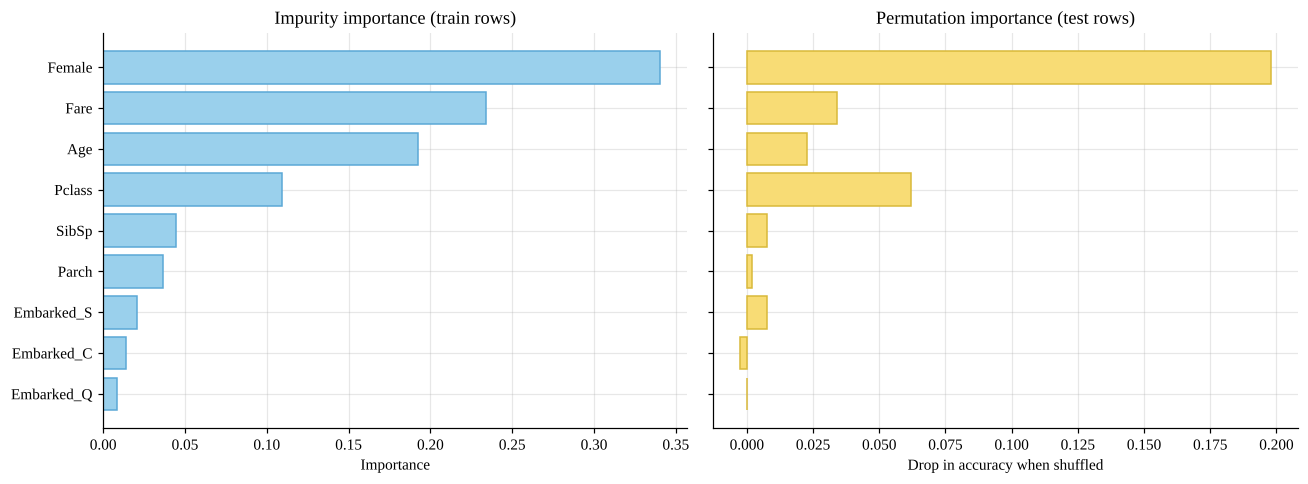

,impurity,permutation
Female,0.340,0.198
Fare,0.234,0.034
Age,0.193,0.023
Pclass,0.109,0.062
SibSp,0.044,0.007
Parch,0.037,0.002
Embarked_S,0.021,0.008
Embarked_C,0.014,-0.003
Embarked_Q,0.008,0.000


In [4]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED).fit(X_train, y_train)

impurity = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
perm = permutation_importance(rf, X_test, y_test, n_repeats=30, random_state=SEED, scoring='accuracy')
perm = pd.Series(perm.importances_mean, index=FEATURES).reindex(impurity.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(impurity.index, impurity.values, color=SKY, edgecolor=SKY_EDGE)
axes[0].set_title('Impurity importance (train rows)')
axes[0].set_xlabel('Importance')
axes[1].barh(perm.index, perm.values, color=YELLOW, edgecolor=YELLOW_EDGE)
axes[1].set_title('Permutation importance (test rows)')
axes[1].set_xlabel('Drop in accuracy when shuffled')
plt.tight_layout()
plt.show()
pd.DataFrame({'impurity': impurity, 'permutation': perm}).sort_values('impurity', ascending=False).round(3)

### **Q3 (c) · Classification report and confusion matrix**

In [5]:
pred = rf.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 3))
print()
print(classification_report(y_test, pred, target_names=LABELS, digits=3))

Test accuracy: 0.804

                 precision    recall  f1-score   support

Did not survive      0.810     0.891     0.848       110
       Survived      0.793     0.667     0.724        69

       accuracy                          0.804       179
      macro avg      0.802     0.779     0.786       179
   weighted avg      0.803     0.804     0.801       179



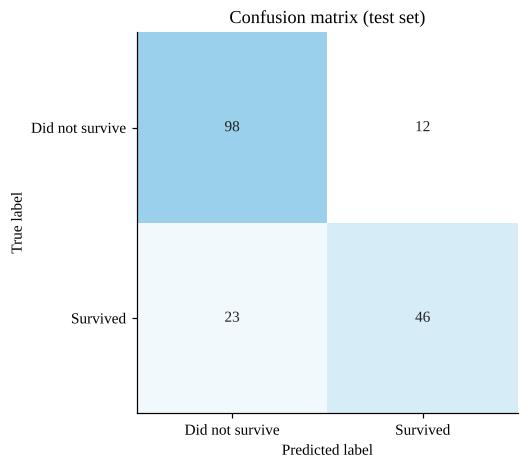

In [6]:
cm = confusion_matrix(y_test, pred)
disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
fig, ax = plt.subplots(figsize=(5, 4.5))
disp.plot(ax=ax, cmap=PASTEL, colorbar=False, values_format='d')
ax.grid(False)
for t in ax.texts:
    t.set_color('#222222')
ax.set_title('Confusion matrix (test set)')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.show()

### **Q3 (d) · False positives, false negatives, recall**

In [7]:
tn, fp, fn, tp = cm.ravel()
recall_survived = tp / (tp + fn)
recall_died = tn / (tn + fp)
print(f'False positives: {fp} passengers predicted Survived who did not survive.')
print(f'False negatives: {fn} passengers predicted Did not survive who actually survived.')
print(f'Recall, Did not survive: {recall_died:.3f}')
print(f'Recall, Survived:        {recall_survived:.3f}')
print('Higher recall:', LABELS[int(recall_survived > recall_died)])

False positives: 12 passengers predicted Survived who did not survive.
False negatives: 23 passengers predicted Did not survive who actually survived.
Recall, Did not survive: 0.891
Recall, Survived:        0.667
Higher recall: Did not survive


### **Q3 (e) · Limiting tree depth**

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for depth in [1, 2, 4, 8]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train, y_train)
    cv_acc = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=SEED), X_train, y_train, cv=cv)
    rows.append({'max_depth': depth, 'actual depth': tree.get_depth(), 'leaves': tree.get_n_leaves(),
                 'training accuracy': tree.score(X_train, y_train), 'CV accuracy': cv_acc.mean(),
                 'test accuracy': tree.score(X_test, y_test)})
depth_table = pd.DataFrame(rows).round(3)
depth_table

,max_depth,actual depth,leaves,training accuracy,CV accuracy,test accuracy
0,1,1,2,0.789,0.789,0.777
1,2,2,4,0.805,0.791,0.760
2,4,4,15,0.841,0.810,0.788
3,8,8,70,0.924,0.792,0.810


In [9]:
for depth in [1, 2]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train, y_train)
    print(f'--- max_depth={depth} ---')
    print(export_text(tree, feature_names=FEATURES, class_names=['died', 'survived']))

--- max_depth=1 ---
|--- Female <= 0.50
|   |--- class: died
|--- Female >  0.50
|   |--- class: survived

--- max_depth=2 ---
|--- Female <= 0.50
|   |--- Age <= 3.50
|   |   |--- class: survived
|   |--- Age >  3.50
|   |   |--- class: died
|--- Female >  0.50
|   |--- Pclass <= 2.50
|   |   |--- class: survived
|   |--- Pclass >  2.50
|   |   |--- class: died



### **Q3 (f) · Predictions file and expected accuracy**

In [10]:
local_submission = pd.DataFrame({'PassengerId': test_raw['PassengerId'].values, 'Survived': pred})
local_submission.to_csv('local_test_predictions.csv', index=False)
print(local_submission.shape, '| local test accuracy:', round(accuracy_score(y_test, pred), 3))
local_submission.head()

(179, 2) | local test accuracy: 0.804


,PassengerId,Survived
0,566,0
1,161,0
2,554,0
3,861,0
4,242,1


In [11]:
fill_all = learn_fill(titanic)
X_all, y_all = prepare(titanic, fill_all), titanic['Survived']
final = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED)
cv_scores = cross_val_score(final, X_all, y_all, cv=cv)
print('Median age from all rows:', fill_all['Age'])
print(f'5-fold CV accuracy: {cv_scores.mean():.3f} (std {cv_scores.std():.3f})')
final.fit(X_all, y_all)

if os.path.exists('test.csv'):
    kaggle_test = pd.read_csv('test.csv')
    sub = pd.DataFrame({'PassengerId': kaggle_test['PassengerId'],
                        'Survived': final.predict(prepare(kaggle_test, fill_all))})
    sub.to_csv('submission.csv', index=False)
    print('submission.csv written:', sub.shape)
else:
    print('test.csv not found: put the Kaggle test.csv next to this notebook to create submission.csv')

Median age from all rows: 28.0
5-fold CV accuracy: 0.842 (std 0.009)
submission.csv written: (418, 2)


### **Q3 (g) · Improved model with extra features**

In [12]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold

RARE = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs', 'Lady': 'Rare', 'Countess': 'Rare', 'Capt': 'Rare',
        'Col': 'Rare', 'Don': 'Rare', 'Dr': 'Rare', 'Major': 'Rare', 'Rev': 'Rare', 'Sir': 'Rare',
        'Jonkheer': 'Rare', 'Dona': 'Rare'}
BASE_COLS = ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'HasCabin', 'Pclass']


def add_features(frame):
    d = frame.copy()
    d['Title'] = d['Name'].str.extract(r',\s*([^.]+)\.')[0].str.strip().replace(RARE)
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['HasCabin'] = d['Cabin'].notna().astype(int)
    return d


def ticket_survival(train, y, other, same_rows):
    stats = pd.Series(np.asarray(y), index=train.index).groupby(train['Ticket'].values).agg(['sum', 'count'])
    total = other['Ticket'].map(stats['sum']).fillna(0).to_numpy()
    count = other['Ticket'].map(stats['count']).fillna(0).to_numpy()
    if same_rows:
        total, count = total - np.asarray(y), count - 1
    prior = np.mean(y)
    return np.c_[np.where(count > 0, (total + prior) / (count + 1), prior), count]


def design(train, other, y_train):
    median = train[['Age', 'Fare']].median()
    parts = []
    for d in (train, other):
        d = d.fillna(median)
        parts.append(pd.get_dummies(d[BASE_COLS + ['Sex', 'Embarked', 'Title']], columns=['Sex', 'Embarked', 'Title'], dtype=int))
    X_tr, X_ot = parts[0], parts[1].reindex(columns=parts[0].columns, fill_value=0)
    return (np.c_[X_tr.values, ticket_survival(train, y_train, train, True)],
            np.c_[X_ot.values, ticket_survival(train, y_train, other, False)])


def new_model():
    return GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED)

In [13]:
data = add_features(titanic)
y_all = titanic['Survived'].to_numpy()
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

base_acc, new_acc = [], []
for tr_idx, va_idx in folds.split(data, y_all):
    tr_rows, va_rows = data.iloc[tr_idx], data.iloc[va_idx]
    fill_fold = learn_fill(titanic.iloc[tr_idx])
    base_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED)
    base_model.fit(prepare(titanic.iloc[tr_idx], fill_fold), y_all[tr_idx])
    base_acc.append(base_model.score(prepare(titanic.iloc[va_idx], fill_fold), y_all[va_idx]))
    X_tr, X_va = design(tr_rows, va_rows, y_all[tr_idx])
    new_acc.append(new_model().fit(X_tr, y_all[tr_idx]).score(X_va, y_all[va_idx]))

pd.DataFrame({'model': ['Random forest, raw features', 'Gradient boosting, new features'],
              'CV accuracy': [np.mean(base_acc), np.mean(new_acc)],
              'std': [np.std(base_acc), np.std(new_acc)]}).round(3)

,model,CV accuracy,std
0,"Random forest, raw features",0.831,0.016
1,"Gradient boosting, new features",0.845,0.013


In [14]:
if os.path.exists('test.csv'):
    kaggle_data = add_features(kaggle_test)
    X_fit, X_new = design(data, kaggle_data, y_all)
    improved = pd.DataFrame({'PassengerId': kaggle_test['PassengerId'],
                             'Survived': new_model().fit(X_fit, y_all).predict(X_new)})
    improved.to_csv('submission_improved.csv', index=False)
    print('submission_improved.csv written:', improved.shape)

submission_improved.csv written: (418, 2)


### **Q3 (h) · More features: interactions, bands and ticket counts**

In [15]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

kaggle_test = pd.read_csv('test.csv')
ticket_count = pd.concat([titanic, kaggle_test])['Ticket'].value_counts()


def add_features_v2(frame):
    d = add_features(frame)
    d['Deck'] = d['Cabin'].str[0].fillna('U').replace({'T': 'U', 'G': 'U'})
    d['TicketFreq'] = d['Ticket'].map(ticket_count)
    d['FarePerPerson'] = d['Fare'] / d['TicketFreq']
    return d


def design_v2(train, other, y_train):
    age_median = train.groupby(['Title', 'Pclass'])['Age'].median()
    age_all, fare_all = train['Age'].median(), train['Fare'].median()
    fare_cuts = train['Fare'].quantile([0.25, 0.5, 0.75]).to_numpy()

    def encode_rows(d):
        d = d.copy()
        guess = [age_median.get((t, p), age_all) for t, p in zip(d['Title'], d['Pclass'])]
        d['Age'] = d['Age'].fillna(pd.Series(guess, index=d.index))
        d['Fare'] = d['Fare'].fillna(fare_all)
        d['FarePerPerson'] = d['FarePerPerson'].fillna(fare_all)
        d['Child'] = (d['Age'] < 13).astype(int)
        d['AgeClass'] = d['Age'] * d['Pclass']
        d['AgeFare'] = d['Age'] * d['Fare']
        d['LogFare'] = np.log1p(d['Fare'])
        d['FareBand'] = np.searchsorted(fare_cuts, d['Fare'])
        d['AgeBand'] = np.digitize(d['Age'], [12, 18, 35, 60])
        numeric = BASE_COLS + ['TicketFreq', 'FarePerPerson', 'Child', 'AgeClass', 'AgeFare', 'LogFare', 'FareBand', 'AgeBand']
        categorical = ['Sex', 'Embarked', 'Title', 'Deck']
        return pd.get_dummies(d[numeric + categorical], columns=categorical, dtype=int)

    X_tr = encode_rows(train)
    X_ot = encode_rows(other).reindex(columns=X_tr.columns, fill_value=0)
    return (np.c_[X_tr.values, ticket_survival(train, y_train, train, True)],
            np.c_[X_ot.values, ticket_survival(train, y_train, other, False)])


def forest(**kw):
    return RandomForestClassifier(n_estimators=500, random_state=SEED, **kw)


MODELS = {
    'Random forest': lambda: forest(min_samples_leaf=2),
    'Gradient boosting': new_model,
    'Voting (LR + RF + GB)': lambda: VotingClassifier(
        [('lr', make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000))),
         ('rf', forest(max_depth=7, min_samples_leaf=3)), ('gb', new_model())], voting='soft'),
}

In [16]:
data_v2 = add_features_v2(titanic)
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)
scores = {name: [] for name in MODELS}
for tr_idx, va_idx in folds.split(data_v2, y_all):
    X_tr, X_va = design_v2(data_v2.iloc[tr_idx], data_v2.iloc[va_idx], y_all[tr_idx])
    for name, make in MODELS.items():
        scores[name].append(make().fit(X_tr, y_all[tr_idx]).score(X_va, y_all[va_idx]))

cv_table = pd.DataFrame({'model': list(scores), 'CV accuracy': [np.mean(v) for v in scores.values()],
                         'std': [np.std(v) for v in scores.values()]}).round(3)
cv_table

,model,CV accuracy,std
0,Random forest,0.842,0.015
1,Gradient boosting,0.845,0.021
2,Voting (LR + RF + GB),0.841,0.023


In [17]:
X_fit, X_new = design_v2(data_v2, add_features_v2(kaggle_test), y_all)
best = cv_table.loc[cv_table['CV accuracy'].idxmax(), 'model']
for file, name in [('submission_improved4.csv', best), ('submission_improved5_rf.csv', 'Random forest')]:
    pred = MODELS[name]().fit(X_fit, y_all).predict(X_new)
    pd.DataFrame({'PassengerId': kaggle_test['PassengerId'], 'Survived': pred}).to_csv(file, index=False)
    print(f'{file}: {name}, survival rate {pred.mean():.3f}')

submission_improved4.csv: Gradient boosting, survival rate 0.354
submission_improved5_rf.csv: Random forest, survival rate 0.359
